In [14]:
from pathlib import Path
from typing import Dict, Optional, Tuple, List

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def plot_active_learning_comparison_mpl(
    name_to_results_dir: Dict[str, Path],
    y_col: str = 'elpp',
    x_col: str = 'round',
    y_label: str = 'ELPP',
    x_label: str = 'Active learning iteration',
    name_mapping: Optional[Dict[str, str]] = None,  # NEW: For custom names
    yscale: str = 'linear',  # NEW: For logarithmic scale
    figsize: Tuple[int, int] = (6, 4),
    dpi: int = 200,
    palette: Optional[List[str]] = None,
    ax: Optional[plt.Axes] = None,
) -> Tuple[plt.Figure, plt.Axes]:
    """
    Loads active learning results and creates a comparison plot using Matplotlib.

    For each method, it shows a boxplot of the results at each iteration and
    a line connecting the mean values across iterations.

    Args:
        name_to_results_dir: A dictionary mapping internal method names to the
                             Path of their results directory.
        y_col: The name of the column in the CSV for the y-axis.
        x_col: The name of the column in the CSV for the x-axis.
        y_label: The label for the y-axis.
        x_label: The label for the x-axis.
        name_mapping: An optional dictionary to map the keys from
                      name_to_results_dir to prettier display names for the legend.
                      If a name is not in the map, the original is used.
        yscale: The scale for the y-axis ('linear', 'log', etc.).
        figsize: The size of the figure to create.
        dpi: The resolution of the figure.
        palette: A list of color strings.
        ax: An existing matplotlib Axes object. If None, a new one is created.

    Returns:
        A tuple containing the matplotlib Figure and Axes objects.
    """
    # --- 1. Load and combine data ---
    all_dfs = []
    method_names = list(name_to_results_dir.keys())

    for name in method_names:
        results_dir = name_to_results_dir[name]
        df_path = results_dir / 'results.csv'
        if df_path.exists():
            df = pd.read_csv(df_path, header=0)
            df['method'] = name
            all_dfs.append(df)
        else:
            print(f"Warning: Could not find 'results.csv' in {results_dir}")

    if not all_dfs:
        raise ValueError("No data could be loaded. Please check paths.")

    combined_df = pd.concat(all_dfs, ignore_index=True)
    combined_df['method'] = pd.Categorical(combined_df['method'], categories=method_names, ordered=True)

    # --- 2. Set up the plot ---
    if ax is None:
        fig, ax = plt.subplots(figsize=figsize, dpi=dpi)
    else:
        fig = ax.get_figure()

    rounds = sorted(combined_df[x_col].unique())
    n_methods = len(method_names)

    if palette is None:
        palette = [f'C{i}' for i in range(n_methods)]

    # --- 3. Calculate positions for grouped boxplots ---
    x_indices = np.arange(len(rounds))
    total_width = 0.6  # Increased width for better spacing
    single_width = total_width / n_methods

    # --- 4. Plot Boxplots and Mean Lines ---
    for i, method in enumerate(method_names):
        # MODIFIED: Get the display name from the mapping, or use original if not found.
        display_name = name_mapping.get(method, method) if name_mapping else method

        positions = x_indices - (total_width / 2) + (i + 0.5) * single_width
        data_to_plot = [
            combined_df[(combined_df['method'] == method) & (combined_df[x_col] == r)][y_col].values
            for r in rounds
        ]

        bp = ax.boxplot(
            data_to_plot,
            positions=positions,
            widths=single_width,
            patch_artist=True,
            showfliers=False,
            medianprops={'color': 'black', 'linewidth': 1.0}
        )

        color = palette[i]
        for patch in bp['boxes']:
            patch.set_facecolor(color)
            patch.set_alpha(0.6)

        mean_values = [np.median(d) for d in data_to_plot]
        ax.plot(positions, mean_values, color=color, marker='o', linestyle='-', label=display_name)

    # --- 5. Customize the plot ---
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)

    # NEW: Apply the y-scale
    ax.set_yscale(yscale)

    ax.set_xticks(x_indices)
    ax.set_xticklabels(rounds)
    ax.legend(title='Method')
    fig.tight_layout()

    return fig, ax

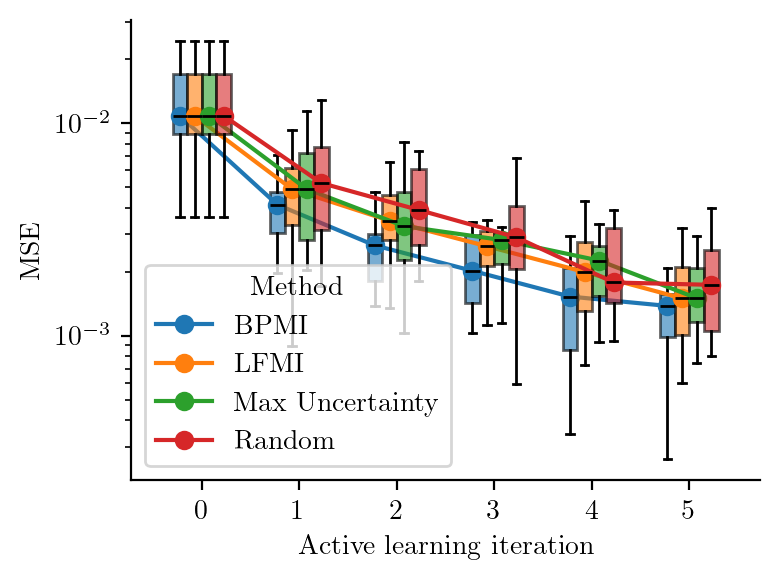

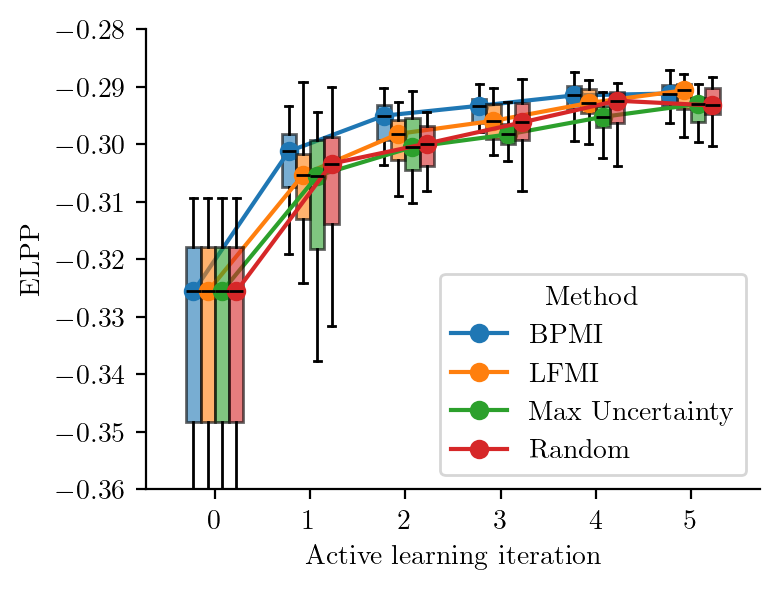

In [15]:
results_to_plot_dir = Path('/home/murray/Projects/psaap-active-learning/output/ToyLinear/comparison10')
result_paths = list(sorted(results_to_plot_dir.glob('2025*')))

# 1. Create the mapping from the internal strategy name to its result path
#    The keys here should match the name in the directory, e.g., 'MaxUncertaintyStrategy'
name_to_results_dir = {
    x.name.split("_")[2]: x for x in result_paths
}

# 2. Create a mapping from the internal name to the desired display name
display_name_map = {
    "RandomStrategy(gamma=0.9000)": "Random",
    "MaxUncertaintyStrategy(beta=0.5, gamma=0.9)": "Max Uncertainty",
    "MutualInformationBMFALStrategy": "LFMI",
    "MutualInformationBMFALNweightedStrategy": "BMFAL-MI (N-weighted)",
    "BatchBALDBMFALStrategy": "BatchBALD-BMFAL",
    "MutualInformationBernoulliPStrategy": "MI (Bernoulli p)",
    "MutualInformationBernoulliPRepeatsStrategy(N=5,jitter=0.01)": "BPMI",
}

name_to_results_dir_keys = sorted(name_to_results_dir, key=lambda x: display_name_map[x])
name_to_results_dir = {x: name_to_results_dir[x] for x in name_to_results_dir_keys}


# --- Plot MSE with a logarithmic y-axis and custom names ---
fig_mse, ax_mse = plot_active_learning_comparison_mpl(
    name_to_results_dir,
    figsize=(4, 3),
    y_col='mse',
    x_col='round',
    y_label='MSE',
    x_label='Active learning iteration',
    name_mapping=display_name_map,  # Pass the custom names
    yscale='log'  # Use logarithmic scale
)
# You can still set ylim if needed, but often autoscale works well with log
# ax_mse.set_ylim(1e-3, 1e-1) # Example for log scale
fig_mse.savefig("toylinear_mse_comparison_log.pdf")


# --- Plot ELPP with a linear y-axis and custom names ---
fig_elpp, ax_elpp = plot_active_learning_comparison_mpl(
    name_to_results_dir,
    figsize=(4, 3),
    y_col='elpp',
    x_col='round',
    y_label='ELPP',
    x_label='Active learning iteration',
    name_mapping=display_name_map,  # Pass the custom names
    yscale='linear' # Default, but explicit here
)
ax_elpp.set_ylim(-0.36, -0.28)
fig_elpp.savefig("toylinear_elpp_comparison.pdf")

plt.show()

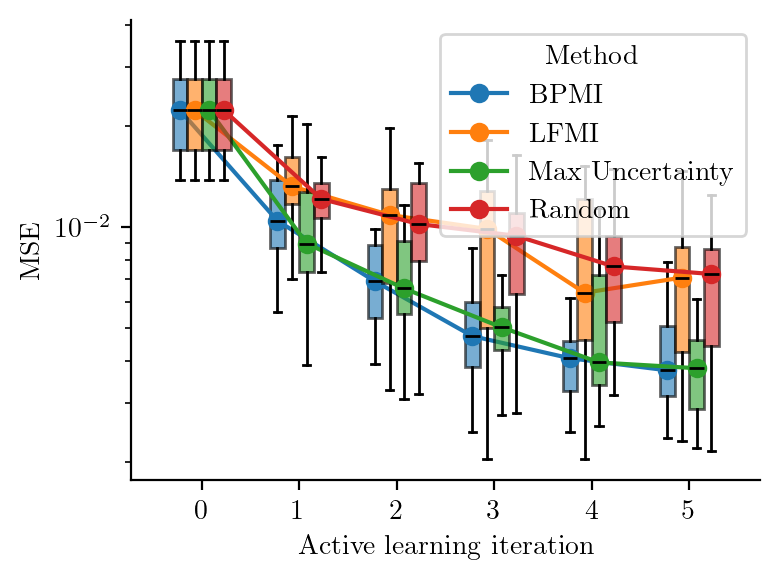

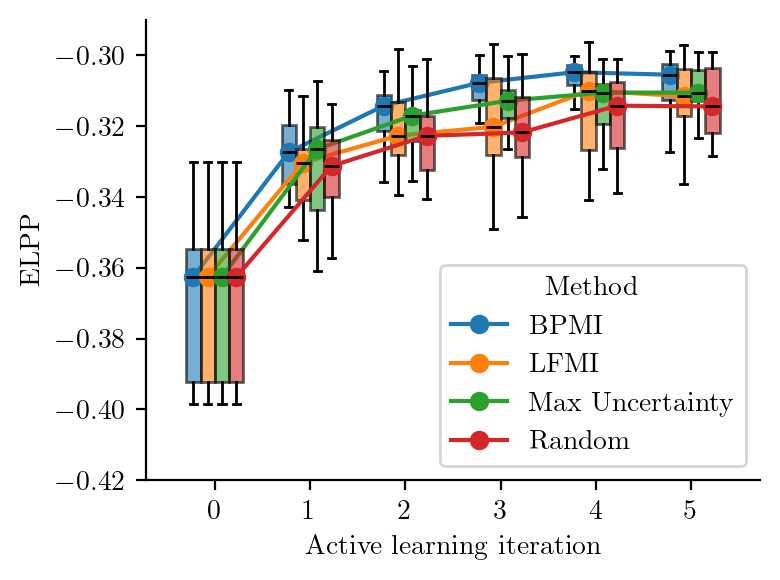

In [19]:
results_to_plot_dir = Path('/home/murray/Projects/psaap-active-learning/output/ToyNonLinear/comparison10')
result_paths = list(sorted(results_to_plot_dir.glob('2025*')))

# 1. Create the mapping from the internal strategy name to its result path
#    The keys here should match the name in the directory, e.g., 'MaxUncertaintyStrategy'
name_to_results_dir = {
    x.name.split("_")[2]: x for x in result_paths
}

# 2. Create a mapping from the internal name to the desired display name
display_name_map = {
    "RandomStrategy(gamma=0.9000)": "Random",
    "MaxUncertaintyStrategy(beta=0.5, gamma=0.9)": "Max Uncertainty",
    "MutualInformationBMFALStrategy": "LFMI",
    "MutualInformationBMFALNweightedStrategy": "BMFAL-MI (N-weighted)",
    "BatchBALDBMFALStrategy": "BatchBALD-BMFAL",
    "MutualInformationBernoulliPStrategy": "MI (Bernoulli p)",
    "MutualInformationBernoulliPRepeatsStrategy(N=5,jitter=0.01)": "BPMI",
}

name_to_results_dir_keys = sorted(name_to_results_dir, key=lambda x: display_name_map[x])
name_to_results_dir = {x: name_to_results_dir[x] for x in name_to_results_dir_keys}


# --- Plot MSE with a logarithmic y-axis and custom names ---
fig_mse, ax_mse = plot_active_learning_comparison_mpl(
    name_to_results_dir,
    figsize=(4, 3),
    y_col='mse',
    x_col='round',
    y_label='MSE',
    x_label='Active learning iteration',
    name_mapping=display_name_map,  # Pass the custom names
    yscale='log'  # Use logarithmic scale
)
# You can still set ylim if needed, but often autoscale works well with log
# ax_mse.set_ylim(1e-3, 1e-1) # Example for log scale
fig_mse.savefig("toynonlinear_mse_comparison_log.pdf")


# --- Plot ELPP with a linear y-axis and custom names ---
fig_elpp, ax_elpp = plot_active_learning_comparison_mpl(
    name_to_results_dir,
    figsize=(4, 3),
    y_col='elpp',
    x_col='round',
    y_label='ELPP',
    x_label='Active learning iteration',
    name_mapping=display_name_map,  # Pass the custom names
    yscale='linear' # Default, but explicit here
)
ax_elpp.set_ylim(-0.42, -0.29)
fig_elpp.savefig("toynonlinear_elpp_comparison.pdf")

plt.show()